In [7]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [8]:
# Load daatset
df = pd.read_csv("spaceship_titanic_cleaned.csv")
print("Dataset shape:", df.shape)

Dataset shape: (8693, 16)


In [9]:
# Verify no missing values
print("Missing values:")
display(df.isnull().sum().to_frame("Missing Values"))

Missing values:


,Missing Values
PassengerId,0
HomePlanet,0
CryoSleep,0
Destination,0
Age,0
VIP,0
RoomService,0
FoodCourt,0
ShoppingMall,0
Spa,0


In [10]:
# Data preparation
df = df.dropna(subset=["Transported"]).copy()

# Convert the target to Boolean values 
if df["Transported"].dtype == "object":
    target = df["Transported"].astype(str).str.strip().str.lower()
    df["Transported"] = target.map({
        "true": True,
        "false": False,
        "1": True,
        "0": False
    })

y = df["Transported"].astype(bool)
columns_to_drop = ["Transported"]
if "PassengerId" in df.columns:
    columns_to_drop.append("PassengerId")
X = df.drop(columns=columns_to_drop).copy()

# Convert Boolean input features into categorical strings
for column in X.select_dtypes(include=["bool"]).columns:
    X[column] = X[column].astype(str)
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

print("Input features:", X.shape[1])
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

print("\nTarget distribution:")
display(y.value_counts().to_frame("Passenger Count"))

Input features: 14
Numeric features: ['Age', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'TotalSpending']
Categorical features: ['HomePlanet', 'CryoSleep', 'Destination', 'VIP', 'Deck', 'CabinSide', 'AgeGroup']

Target distribution:


,Passenger Count
Transported,
True,4378
False,4315


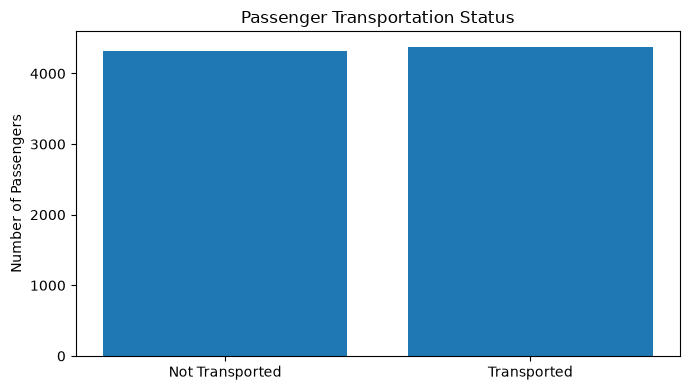

Overall transport rate: 50.36 %


In [11]:
# EDA
target_counts = y.value_counts().reindex([False, True], fill_value=0)
plt.figure(figsize=(7, 4))
plt.bar(["Not Transported", "Transported"],target_counts.values)
plt.title("Passenger Transportation Status")
plt.ylabel("Number of Passengers")
plt.tight_layout()
plt.show()

print("Overall transport rate:", round(y.mean() * 100, 2), "%")

In [12]:
# Transaported rates with different attributes
eda_df = df.copy()
eda_df["Transported"] = y.astype(int)

for column in ["CryoSleep", "HomePlanet", "Destination", "Deck", "AgeGroup"]:
    if column in eda_df.columns:
        print(f"\nTransportation rate by {column}:")

        rate = (
            eda_df.groupby(column, dropna=False)["Transported"]
            .mean()
            .mul(100)
            .round(2)
        )

        display(rate.to_frame("Transport Rate (%)"))


Transportation rate by CryoSleep:


,Transport Rate (%)
CryoSleep,
False,33.50
True,81.76



Transportation rate by HomePlanet:


,Transport Rate (%)
HomePlanet,
Earth,42.76
Europa,65.88
Mars,52.30



Transportation rate by Destination:


,Transport Rate (%)
Destination,
55 Cancri e,61.00
PSO J318.5-22,50.38
TRAPPIST-1e,47.22



Transportation rate by Deck:


,Transport Rate (%)
Deck,
A,49.61
B,73.43
C,68.01
D,43.31
E,35.73
F,43.99
G,51.62
T,20.00
Unknown,50.25



Transportation rate by AgeGroup:


,Transport Rate (%)
AgeGroup,
Adult,47.94
Child,69.98
Senior,48.44
Teen,55.35
Young Adult,47.26


In [13]:
# Split training data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 6954
Testing records: 1739


In [14]:
# Data preprocessing
try:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", encoder)
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ],
    remainder="drop",
    sparse_threshold=0
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [15]:
# Apply the preprocessing pipeline

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Convert target values into integers (0 and 1)
y_train_array = y_train.astype(int).to_numpy()
y_test_array = y_test.astype(int).to_numpy()

# Check the results
print("Preprocessing completed successfully!")
print("X_train_processed shape:", X_train_processed.shape)
print("X_test_processed shape:", X_test_processed.shape)
print("y_train_array shape:", y_train_array.shape)
print("y_test_array shape:", y_test_array.shape)

Preprocessing completed successfully!
X_train_processed shape: (6954, 34)
X_test_processed shape: (1739, 34)
y_train_array shape: (6954,)
y_test_array shape: (1739,)


In [16]:
# Applying logistic regression
import numpy as np
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))
def calculate_loss(y_true, probabilities):
    epsilon = 1e-15

    probabilities = np.clip(
        probabilities,
        epsilon,
        1 - epsilon
    )

    loss = -np.mean(
        y_true * np.log(probabilities)
        + (1 - y_true) * np.log(1 - probabilities)
    )

    return loss

def train_logistic_regression(
    X,
    y,
    learning_rate=0.01,
    epochs=2000
):
    number_of_samples, number_of_features = X.shape

    # Initialize weights and bias
    weights = np.zeros(number_of_features)
    bias = 0.0

    loss_history = []

    for epoch in range(epochs):

        # Calculate scores
        z = np.dot(X, weights) + bias

        # Calculate predicted probabilities
        probabilities = sigmoid(z)

        # Calculate loss
        loss = calculate_loss(y, probabilities)
        loss_history.append(loss)

        # Calculate gradients
        dw = np.dot(X.T, probabilities - y) / number_of_samples
        db = np.mean(probabilities - y)

        # Update weights and bias
        weights -= learning_rate * dw
        bias -= learning_rate * db

        if (epoch + 1) % 500 == 0:
            print(
                f"Epoch {epoch + 1}, Loss: {loss:.4f}"
            )

    return weights, bias, loss_history


# Training 
weights, bias, loss_history = train_logistic_regression(
    X_train_processed,
    y_train_array,
    learning_rate=0.01,
    epochs=2000
)
print("\nLogistic Regression training completed!")
print("Number of weights:", len(weights))
print("Final loss:", loss_history[-1])

# Checking on testing data 
# Calculate prediction probabilities
def predict_probability(X, weights, bias):
    z = np.dot(X, weights) + bias
    return sigmoid(z)
# Convert probabilities into class predictions
def predict_class(X, weights, bias, threshold=0.5):
    probabilities = predict_probability(X, weights, bias)
    return (probabilities >= threshold).astype(int)
# Predict on testing data
y_pred = predict_class(
    X_test_processed,
    weights,
    bias)
# Get probabilities as well
y_prob = predict_probability(
    X_test_processed,
    weights,
    bias)

print("\nFirst 10 actual values:", y_test_array[:10])
print("First 10 predicted values:", y_pred[:10])
print("First 10 probabilities:", np.round(y_prob[:10], 3))

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

accuracy = accuracy_score(y_test_array, y_pred)
precision = precision_score(y_test_array, y_pred, zero_division=0)
recall = recall_score(y_test_array, y_pred, zero_division=0)
f1 = f1_score(y_test_array, y_pred, zero_division=0)

print("\nLOGISTIC REGRESSION RESULTS")
print("---------------------------")
print(f"Accuracy:  {accuracy * 100:.2f}%")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_array, y_pred))


Epoch 500, Loss: 0.5352
Epoch 1000, Loss: 0.4928
Epoch 1500, Loss: 0.4742
Epoch 2000, Loss: 0.4642

Logistic Regression training completed!
Number of weights: 34
Final loss: 0.464247568560916

First 10 actual values: [1 0 0 1 0 0 1 1 0 1]
First 10 predicted values: [1 1 0 1 0 1 1 1 0 1]
First 10 probabilities: [0.851 0.8   0.253 0.635 0.362 0.742 0.861 0.62  0.281 0.662]

LOGISTIC REGRESSION RESULTS
---------------------------
Accuracy:  77.29%
Precision: 0.8002
Recall:    0.7317
F1-score:  0.7645

Confusion Matrix:
[[703 160]
 [235 641]]


In [17]:
# Apply decision tree
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,)

class DecisionTreeScratch:

    def __init__(self, max_depth=6, min_samples_split=10):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.tree = None

    # Calculate Gini impurity
    def gini(self, y):
        if len(y) == 0:
            return 0

        probabilities = np.bincount(
            y.astype(int), minlength=2
        ) / len(y)

        return 1 - np.sum(probabilities ** 2)

    # Find the best feature and threshold
    def best_split(self, X, y):
        best_gain = 0
        best_feature = None
        best_threshold = None

        parent_gini = self.gini(y)
        n_samples, n_features = X.shape

        for feature in range(n_features):
            thresholds = np.unique(X[:, feature])

            # Reduce the number of thresholds checked
            if len(thresholds) > 30:
                thresholds = np.quantile(
                    thresholds,
                    np.linspace(0.05, 0.95, 20)
                )
                thresholds = np.unique(thresholds)

            for threshold in thresholds:
                left_mask = X[:, feature] <= threshold
                right_mask = ~left_mask

                if not left_mask.any() or not right_mask.any():
                    continue

                y_left = y[left_mask]
                y_right = y[right_mask]

                weighted_gini = (
                    len(y_left) / n_samples * self.gini(y_left)
                    + len(y_right) / n_samples * self.gini(y_right)
                )

                gain = parent_gini - weighted_gini

                if gain > best_gain:
                    best_gain = gain
                    best_feature = feature
                    best_threshold = threshold

        return best_feature, best_threshold, best_gain

    # Build the tree recursively
    def build_tree(self, X, y, depth):
        number_of_ones = np.sum(y)
        number_of_zeros = len(y) - number_of_ones

        # Predict the majority class
        prediction = int(number_of_ones > number_of_zeros)

        # Stop conditions
        if (
            depth >= self.max_depth
            or len(y) < self.min_samples_split
            or len(np.unique(y)) == 1
        ):
            return {"prediction": prediction}

        feature, threshold, gain = self.best_split(X, y)

        if feature is None or gain <= 0:
            return {"prediction": prediction}

        left_mask = X[:, feature] <= threshold
        right_mask = ~left_mask

        return {
            "feature": feature,
            "threshold": threshold,
            "left": self.build_tree(
                X[left_mask], y[left_mask], depth + 1
            ),
            "right": self.build_tree(
                X[right_mask], y[right_mask], depth + 1
            ),
            "prediction": prediction
        }

    # Train the Decision Tree
    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=int).ravel()

        self.tree = self.build_tree(X, y, depth=0)

        return self

    # Predict one sample
    def predict_one(self, sample, node):
        if "feature" not in node:
            return node["prediction"]

        feature = node["feature"]
        threshold = node["threshold"]

        if sample[feature] <= threshold:
            return self.predict_one(sample, node["left"])

        return self.predict_one(sample, node["right"])

    # Predict multiple samples
    def predict(self, X):
        X = np.asarray(X, dtype=float)

        return np.array([
            self.predict_one(sample, self.tree)
            for sample in X
        ])



# Training
decision_tree = DecisionTreeScratch(
    max_depth=6,
    min_samples_split=10)

decision_tree.fit(
    X_train_processed,
    y_train_array.astype(int)
)

print("Decision Tree training completed!")


# Test on testing data
y_pred_tree = decision_tree.predict(X_test_processed)
print("\nFirst 10 actual values:")
print(y_test_array[:10])
print("\nFirst 10 predictions:")
print(y_pred_tree[:10])



# Evaluation
accuracy_tree = accuracy_score(
    y_test_array, y_pred_tree
)

precision_tree = precision_score(
    y_test_array, y_pred_tree, zero_division=0
)

recall_tree = recall_score(
    y_test_array, y_pred_tree, zero_division=0
)

f1_tree = f1_score(
    y_test_array, y_pred_tree, zero_division=0
)

print("\n========== DECISION TREE RESULTS ==========")

print(f"Accuracy:  {accuracy_tree * 100:.2f}%")
print(f"Precision: {precision_tree * 100:.2f}%")
print(f"Recall:    {recall_tree * 100:.2f}%")
print(f"F1-score:  {f1_tree * 100:.2f}%")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_array, y_pred_tree))


Decision Tree training completed!

First 10 actual values:
[1 0 0 1 0 0 1 1 0 1]

First 10 predictions:
[1 1 0 1 1 1 1 1 0 1]

========== DECISION TREE RESULTS ==========
Accuracy:  78.26%
Precision: 73.90%
Recall:    87.90%
F1-score:  80.29%

Confusion Matrix:
[[591 272]
 [106 770]]


In [19]:
# Applyimng KNN
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

class KNN:

    def __init__(self, k=5):
        self.k = k
        self.X_train = None
        self.y_train = None

    # Train the model by storing training data
    def fit(self, X, y):
        self.X_train = np.asarray(X, dtype=float)
        self.y_train = np.asarray(y, dtype=int).ravel()

        return self

    # Calculate Euclidean distance
    def euclidean_distance(self, sample1, sample2):
        return np.sqrt(np.sum((sample1 - sample2) ** 2))

    # Predict the class of one sample
    def predict_one(self, sample):

        # Calculate distances from the sample to all training samples
        distances = np.sqrt(
            np.sum((self.X_train - sample) ** 2, axis=1)
        )

        # Find indices of the k nearest neighbors
        nearest_indices = np.argsort(distances)[:self.k]

        # Get the classes of the nearest neighbors
        nearest_labels = self.y_train[nearest_indices]

        # Majority voting
        counts = np.bincount(nearest_labels, minlength=2)

        return int(np.argmax(counts))

    # Predict multiple samples
    def predict(self, X):
        X = np.asarray(X, dtype=float)

        return np.array([
            self.predict_one(sample)
            for sample in X
        ])


# Training
knn_model = KNN(k=5)
knn_model.fit(
    X_train_processed,
    y_train_array.astype(int)
)

print("KNN model training completed!")
y_pred_knn = knn_model.predict(X_test_processed)
print("\nFirst 10 actual values:")
print(y_test_array[:10])
print("\nFirst 10 predictions:")
print(y_pred_knn[:10])

# Evaluation
accuracy_knn = accuracy_score(
    y_test_array, y_pred_knn
)
precision_knn = precision_score(
    y_test_array, y_pred_knn, zero_division=0
)
recall_knn = recall_score(
    y_test_array, y_pred_knn, zero_division=0
)
f1_knn = f1_score(
    y_test_array, y_pred_knn, zero_division=0
)

 
print("\n========== KNN RESULTS ==========")
print(f"Accuracy:  {accuracy_knn * 100:.2f}%")
print(f"Precision: {precision_knn * 100:.2f}%")
print(f"Recall:    {recall_knn * 100:.2f}%")
print(f"F1-score:  {f1_knn * 100:.2f}%")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test_array, y_pred_knn))


KNN model training completed!

First 10 actual values:
[1 0 0 1 0 0 1 1 0 1]

First 10 predictions:
[1 0 0 1 1 0 1 0 0 1]

========== KNN RESULTS ==========
Accuracy:  77.29%
Precision: 78.00%
Recall:    76.48%
F1-score:  77.23%

Confusion Matrix:
[[674 189]
 [206 670]]


In [ ]:
# Applying Naive Byes 
class NaiveBayes:
    def __init__(self):
        self.classes = None
        self.priors = {}
        self.means = {}
        self.variances = {}

    # Train the model
    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=int).ravel()
        self.classes = np.unique(y)

        for c in self.classes:

            # Select samples belonging to this class
            X_class = X[y == c]
            # Calculate class probability
            self.priors[c] = len(X_class) / len(X)
            # Calculate mean and variance of each feature
            self.means[c] = np.mean(X_class, axis=0)
            self.variances[c] = np.var(X_class, axis=0)

        # Prevent division by zero for constant features
        all_variances = np.var(X, axis=0)
        variance_floor = 1e-9 * max(
            float(np.max(all_variances)), 1.0)
        for c in self.classes:
            self.variances[c] = np.maximum(
                self.variances[c], variance_floor)
        return self

    # Calculate log probability using Gaussian distribution
    def calculate_log_probability(self, X, c):
        mean = self.means[c]
        variance = self.variances[c]
        log_likelihood = -0.5 * np.sum(
            np.log(2 * np.pi * variance)
            + ((X - mean) ** 2) / variance,
            axis=1)

        log_prior = np.log(self.priors[c])
        return log_prior + log_likelihood

    # Predict the class of each sample
    def predict(self, X):
        X = np.asarray(X, dtype=float)
        class_scores = np.array([
            self.calculate_log_probability(X, c)
            for c in self.classes
        ]).T
        best_indices = np.argmax(class_scores, axis=1)
        return self.classes[best_indices]



# Training
naive_bayes = NaiveBayesScratch()
naive_bayes.fit(
    X_train_processed,
    y_train_array
)
print("Naive Bayes model training completed!")

y_pred_nb = naive_bayes.predict(X_test_processed)
print("\nFirst 10 actual values:")
print(y_test_array[:10])
print("\nFirst 10 predictions:")
print(y_pred_nb[:10])

# Evaluation
accuracy_nb = accuracy_score(
    y_test_array, y_pred_nb)
precision_nb = precision_score(
    y_test_array, y_pred_nb, zero_division=0)
recall_nb = recall_score(
    y_test_array, y_pred_nb, zero_division=0)
f1_nb = f1_score(
    y_test_array, y_pred_nb, zero_division=0)

print("\n========== NAIVE BAYES RESULTS ==========")
print(f"Accuracy:  {accuracy_nb * 100:.2f}%")
print(f"Precision: {precision_nb * 100:.2f}%")
print(f"Recall:    {recall_nb * 100:.2f}%")
print(f"F1-score:  {f1_nb * 100:.2f}%")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test_array, y_pred_nb))
